# Exploratory Data Analysis: UCI Adult

This notebook loads the original [UCI Adult dataset](https://archive.ics.uci.edu/dataset/2/adult)
and checks its structure, missing values, and class distribution.

Install the dependencies from [requirements.txt](../requirements.txt) and run the notebook
with that Python kernel.
The exploratory summaries use the training split. The test split is reserved for final evaluation.

## Load the original training and test files

The data files have no column headers. The feature names are read in order from
[the dataset documentation](../data/adult.names), and `income` is appended as
the target column. The trailing period
in the test income labels is removed so both splits use the same labels.

In [20]:
from pathlib import Path

import pandas as pd

working_dir = Path.cwd()
schema_path = working_dir / "data" / "adult.names"
if not schema_path.is_file():
    schema_path = working_dir.parent / "data" / "adult.names"

if not schema_path.is_file():
    raise FileNotFoundError("Could not find data/adult.names. Run from the repository root or notebooks/.")

data_dir = schema_path.parent
feature_names = []
for line in schema_path.read_text(encoding="utf-8").splitlines():
    line = line.strip()
    if line and not line.startswith("|") and ":" in line:
        feature_names.append(line.split(":", maxsplit=1)[0].strip())

column_names = feature_names + ["income"]

read_options = {
    "names": column_names,
    "header": None,
    "skipinitialspace": True,
    "na_values": "?",
    "comment": "|",
}

train_data = pd.read_csv(data_dir / "adult.data", **read_options)

In [21]:
from IPython.display import display

test_data = pd.read_csv(data_dir / "adult.test", **read_options)
test_data["income"] = test_data["income"].str.removesuffix(".")

## Verify the data structure

Check the dimensions against the original split described by UCI and verify
that both splits contain the expected income labels. Then preview the training data.

In [22]:
assert train_data.shape == (32_561, 15), "Unexpected training file dimensions."
assert test_data.shape == (16_281, 15), "Unexpected test file dimensions."

expected_labels = {"<=50K", ">50K"}
assert set(train_data["income"]) == expected_labels, "Unexpected training labels."
assert set(test_data["income"]) == expected_labels, "Unexpected test labels."

split_summary = pd.DataFrame(
    {
        "rows": [len(train_data), len(test_data)],
        "columns": [train_data.shape[1], test_data.shape[1]],
    },
    index=["Training", "Test"],
)

display(split_summary)
display(train_data.head())

,rows,columns
Training,32561,15
Test,16281,15


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Inspect data types and missing values

The table reports the number and percentage of missing entries in each
training column. These checks guide subsequent preprocessing decisions.

In [23]:
missing_counts = train_data.isna().sum()
column_summary = pd.DataFrame(
    {
        "data_type": train_data.dtypes.astype(str),
        "missing_count": missing_counts,
        "missing_percent": (missing_counts / len(train_data) * 100).round(2),
    }
)

display(column_summary.sort_values("missing_count", ascending=False, kind="stable"))

,data_type,missing_count,missing_percent
occupation,str,1843,5.66
workclass,str,1836,5.64
native-country,str,583,1.79
age,int64,0,0.00
fnlwgt,int64,0,0.00
education,str,0,0.00
education-num,int64,0,0.00
marital-status,str,0,0.00
relationship,str,0,0.00
race,str,0,0.00


## Check the training class distribution

Compare the number and percentage of records in each income category to
see how balanced the prediction task is. Percentages describe the training
records, with one count per row.

In [24]:
income_counts = train_data["income"].value_counts().reindex(["<=50K", ">50K"])
income_summary = pd.DataFrame(
    {
        "count": income_counts,
        "percent": (income_counts / len(train_data) * 100).round(2),
    }
)

display(income_summary)

,count,percent
income,,
<=50K,24720,75.92
>50K,7841,24.08


## Univariate Distributions

Each plot uses the training split. Frequencies and percentages count each record
once. The figures include the distribution of the census weight (`fnlwgt`) itself.

### Numeric summary

The table gives the minimum, 25th percentile, median, 75th percentile, and maximum
for each numeric variable in the training split, including `education-num`.

In [25]:
summary_labels = {
    "min": "Minimum",
    "25%": "25th percentile",
    "50%": "Median",
    "75%": "75th percentile",
    "max": "Maximum",
}
numeric_data = train_data.select_dtypes(include="number")
numeric_summary = numeric_data.describe().T[list(summary_labels)].rename(columns=summary_labels)
display(numeric_summary)

,Minimum,25th percentile,Median,75th percentile,Maximum
age,17.0,28.0,37.0,48.0,90.0
fnlwgt,12285.0,117827.0,178356.0,237051.0,1484705.0
education-num,1.0,9.0,10.0,12.0,16.0
capital-gain,0.0,0.0,0.0,0.0,99999.0
capital-loss,0.0,0.0,0.0,0.0,4356.0
hours-per-week,1.0,40.0,40.0,45.0,99.0


### Age, weekly hours, and census weight

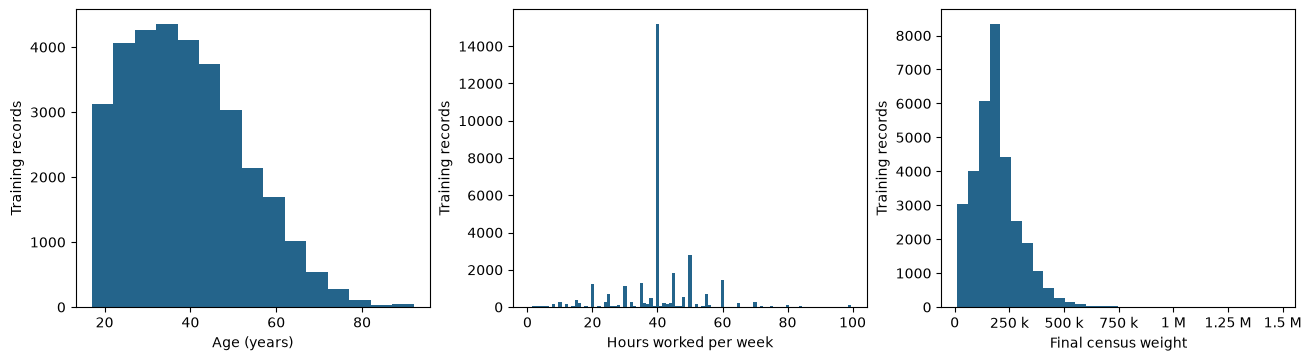

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter, PercentFormatter, StrMethodFormatter

bar_color = "#24648B"
numeric_features = [
    ("age", "Age (years)", range(17, 93, 5)),
    ("hours-per-week", "Hours worked per week", [hour - 0.5 for hour in range(1, 101)]),
    ("fnlwgt", "Final census weight", 30),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for ax, (feature, label, bins) in zip(axes, numeric_features):
    ax.hist(train_data[feature].dropna(), bins=bins, color=bar_color)
    ax.set(xlabel=label, ylabel="Training records")
axes[-1].xaxis.set_major_formatter(EngFormatter())
plt.show()

### Capital gain and capital loss

The top row shows how often each field is zero or positive. The bottom row
shows the distribution among records with positive values, with a logarithmic
count axis to make low-frequency bins visible.

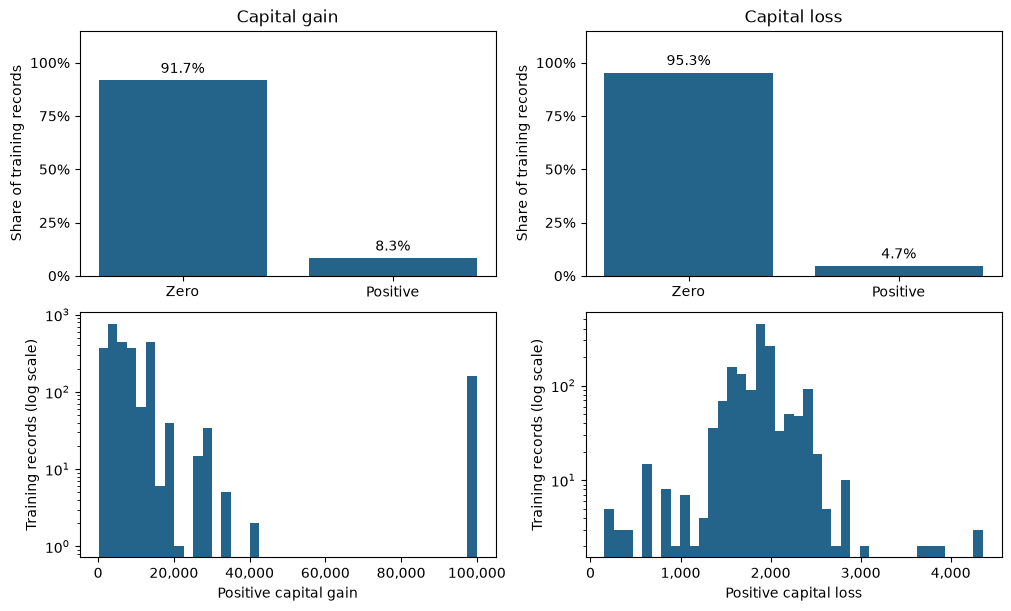

In [27]:
capital_features = [
    ("capital-gain", "Capital gain"),
    ("capital-loss", "Capital loss"),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for (share_ax, amount_ax), (feature, label) in zip(axes.T, capital_features):
    amounts = train_data[feature].dropna()
    positive_amounts = amounts[amounts > 0]
    shares = [amounts.eq(0).mean(), amounts.gt(0).mean()]

    bars = share_ax.bar(["Zero", "Positive"], shares, color=bar_color)
    share_ax.bar_label(bars, labels=[f"{share:.1%}" for share in shares], padding=3)
    share_ax.set(title=label, ylabel="Share of training records", ylim=(0, 1.15))
    share_ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    share_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    amount_ax.hist(positive_amounts, bins=40, log=True, color=bar_color)
    amount_ax.set(xlabel=f"Positive {label.lower()}", ylabel="Training records (log scale)")
    amount_ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

### Categorical features

Bars show the share of all training records. Missing entries appear as
`Missing` wherever they occur.

The tables report category counts and percentages of all training records.
Percentages are shown to three decimal places so rare categories stay visible.

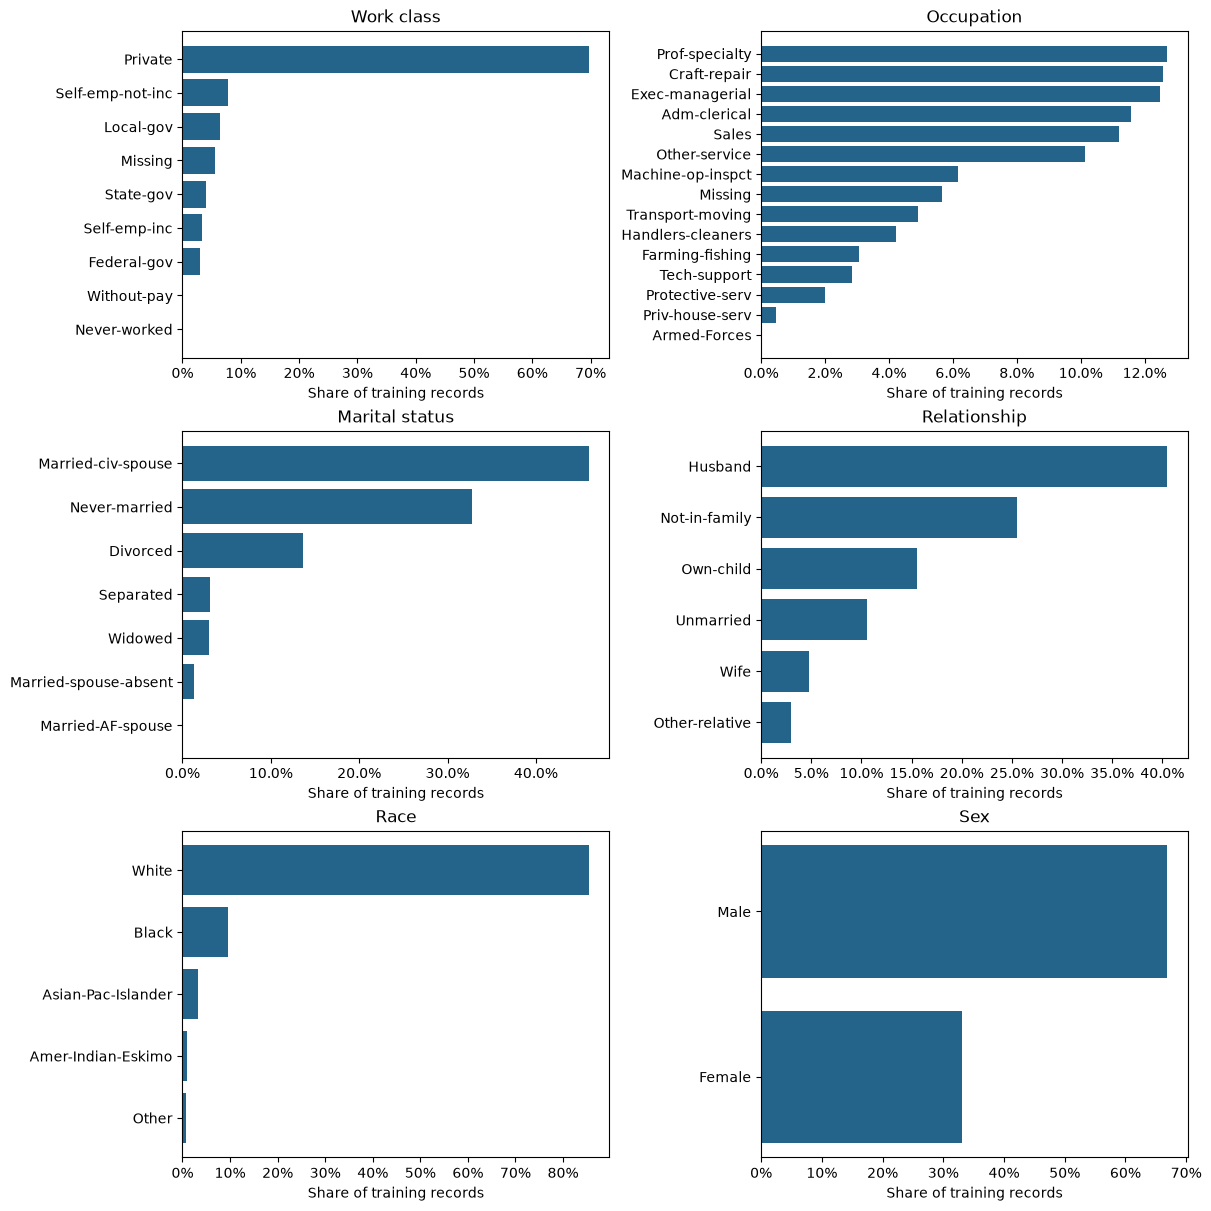

In [28]:
categorical_features = [
    ("workclass", "Work class"),
    ("occupation", "Occupation"),
    ("marital-status", "Marital status"),
    ("relationship", "Relationship"),
    ("race", "Race"),
    ("sex", "Sex"),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12), layout="constrained")
for ax, (feature, label) in zip(axes.flat, categorical_features):
    shares = train_data[feature].fillna("Missing").value_counts(normalize=True)
    ax.barh(shares.index, shares, color=bar_color)
    ax.invert_yaxis()
    ax.set(title=label, xlabel="Share of training records")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.show()

In [29]:
from IPython.display import Markdown

def display_category_summary(counts, label):
    shares = counts / len(train_data)
    summary = pd.DataFrame(
        {"Count": counts, "Percentage": shares.map("{:.3%}".format)}
    ).rename_axis("Category")

    display(Markdown(f"#### {label}"))
    with pd.option_context("display.max_rows", None):
        display(summary)

for feature, label in categorical_features:
    counts = train_data[feature].fillna("Missing").value_counts()
    display_category_summary(counts, label)

#### Work class

,Count,Percentage
Category,,
Private,22696,69.703%
Self-emp-not-inc,2541,7.804%
Local-gov,2093,6.428%
Missing,1836,5.639%
State-gov,1298,3.986%
Self-emp-inc,1116,3.427%
Federal-gov,960,2.948%
Without-pay,14,0.043%
Never-worked,7,0.021%


#### Occupation

,Count,Percentage
Category,,
Prof-specialty,4140,12.715%
Craft-repair,4099,12.589%
Exec-managerial,4066,12.487%
Adm-clerical,3770,11.578%
Sales,3650,11.210%
Other-service,3295,10.119%
Machine-op-inspct,2002,6.148%
Missing,1843,5.660%
Transport-moving,1597,4.905%


#### Marital status

,Count,Percentage
Category,,
Married-civ-spouse,14976,45.994%
Never-married,10683,32.809%
Divorced,4443,13.645%
Separated,1025,3.148%
Widowed,993,3.050%
Married-spouse-absent,418,1.284%
Married-AF-spouse,23,0.071%


... (2 outputs left out)

#### Race

,Count,Percentage
Category,,
White,27816,85.427%
Black,3124,9.594%
Asian-Pac-Islander,1039,3.191%
Amer-Indian-Eskimo,311,0.955%
Other,271,0.832%


#### Sex

,Count,Percentage
Category,,
Male,21790,66.921%
Female,10771,33.079%


### Education and native country

The education chart displays both the category and its `education-num` code
after checking that each category maps to exactly one code and vice versa.
Both charts show categories in descending order of frequency.
The native-country chart shows the ten most frequent recorded countries.
`Other` combines the remaining recorded countries for this figure, and
`Missing` represents records with no country listed.

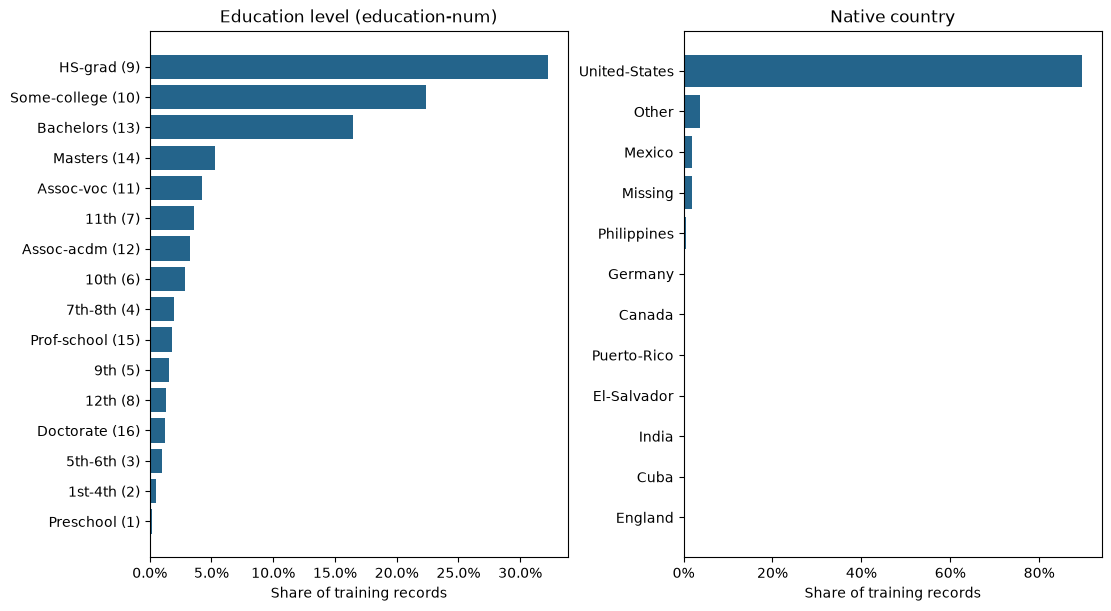

In [30]:
education_levels = train_data[["education", "education-num"]].drop_duplicates()
assert education_levels["education"].is_unique and education_levels["education-num"].is_unique, (
    "Expected a one-to-one mapping between education and education-num."
)
education_levels = education_levels.sort_values("education-num")
education_counts = train_data["education"].value_counts().reindex(education_levels["education"])
education_plot_counts = education_counts.sort_values(ascending=False, kind="stable")
education_codes = education_levels.set_index("education")["education-num"]
education_plot_labels = [
    f"{level} ({education_codes.at[level]})" for level in education_plot_counts.index
]

country_counts = train_data["native-country"].value_counts()
country_plot_counts = country_counts.head(10).copy()
country_plot_counts.loc["Other"] = country_counts.iloc[10:].sum()
country_plot_counts.loc["Missing"] = train_data["native-country"].isna().sum()
country_plot_counts = country_plot_counts.sort_values(ascending=False, kind="stable")

fig, (education_ax, country_ax) = plt.subplots(1, 2, figsize=(11, 6), layout="constrained")
education_ax.barh(
    education_plot_labels, education_plot_counts / len(train_data), color=bar_color
)
education_ax.set_title("Education level (education-num)")
country_ax.barh(
    country_plot_counts.index, country_plot_counts / len(train_data), color=bar_color
)
country_ax.set_title("Native country")
for ax in (education_ax, country_ax):
    ax.invert_yaxis()
    ax.set_xlabel("Share of training records")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.show()

In [17]:
display_category_summary(education_counts, "Education")

full_country_counts = train_data["native-country"].fillna("Missing").value_counts()
display_category_summary(full_country_counts, "Native country")

#### Education

,Count,Percentage
Category,,
Preschool,51,0.157%
1st-4th,168,0.516%
5th-6th,333,1.023%
7th-8th,646,1.984%
9th,514,1.579%
10th,933,2.865%
11th,1175,3.609%
12th,433,1.330%
HS-grad,10501,32.250%


#### Native country

,Count,Percentage
Category,,
United-States,29170,89.586%
Mexico,643,1.975%
Missing,583,1.790%
Philippines,198,0.608%
Germany,137,0.421%
Canada,121,0.372%
Puerto-Rico,114,0.350%
El-Salvador,106,0.326%
India,100,0.307%


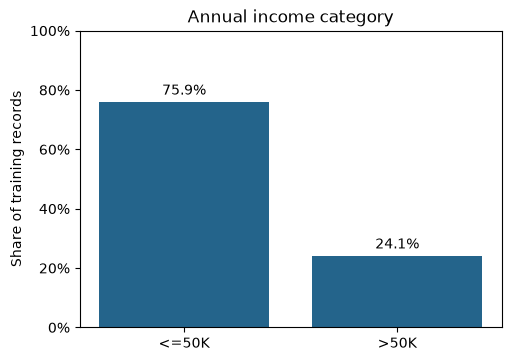

In [31]:
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
income_shares = income_counts / len(train_data)
bars = ax.bar(income_shares.index, income_shares, color=bar_color)
ax.bar_label(bars, labels=[f"{share:.1%}" for share in income_shares], padding=3)
ax.set(title="Annual income category", ylabel="Share of training records", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.show()